In [1]:
import warnings
import pandas as pd
import joblib
import numpy as np

from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from matplotlib import pyplot as plt
from sklearn.exceptions import InconsistentVersionWarning

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="xgboost")

# Load data training and test
df_training = pd.read_csv('dataset/Coords_data_training.csv')
df_test = pd.read_csv('dataset/Coords_data_test.csv')

# Colunas a remover das features de entrada (tudo o que é target)
target_cols = ['sin_2theta', 'cos_2theta', 'movement_sin', 'movement_cos', 'movement_angle']

X_train = df_training.drop(columns=[c for c in target_cols if c in df_training.columns])
Y_train = df_training[['sin_2theta', 'cos_2theta', 'movement_sin', 'movement_cos']]

X_test = df_test.drop(columns=[c for c in target_cols if c in df_test.columns])
Y_test = df_test[['sin_2theta', 'cos_2theta', 'movement_sin', 'movement_cos']]

In [2]:
# Create the model
model = MultiOutputRegressor(XGBRegressor(objective='reg:squarederror', random_state=42))

# Create grid search
param_grid = {
    'estimator__max_depth': [1, 3, 6, 9],
    'estimator__learning_rate': [0.0125, 0.025, 0.05, 0.1],
    'estimator__n_estimators': [225, 50, 75, 100],
    'estimator__subsample': [0.55, 0.7, 0.85, 1.0],
    'estimator__colsample_bytree': [0.55, 0.7, 0.85, 1.0],
    'estimator__min_child_weight': [0, 1, 3, 5],
    'estimator__gamma': [0, 0.1, 0.3, 0.6]
}

grid_search = GridSearchCV(estimator=model, param_grid=param_grid, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1, cv=4)
grid_search.fit(X_train, Y_train)

print("Best parameters:", grid_search.best_params_)

Fitting 4 folds for each of 16384 candidates, totalling 65536 fits


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters: {'estimator__colsample_bytree': 1.0, 'estimator__gamma': 0, 'estimator__learning_rate': 0.025, 'estimator__max_depth': 9, 'estimator__min_child_weight': 5, 'estimator__n_estimators': 225, 'estimator__subsample': 0.7}


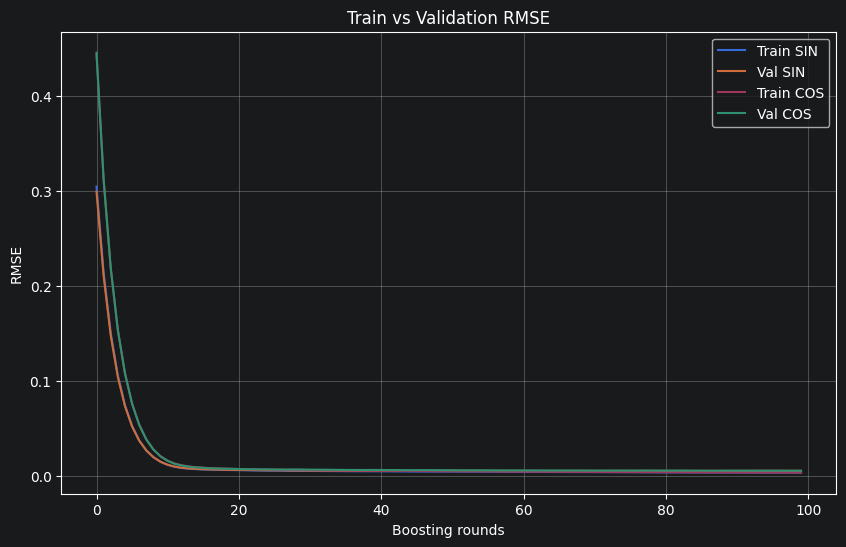

In [3]:
best_model = grid_search.best_estimator_
best_model.estimator.set_params(base_score=0.0)

models = []
histories = []

Y_train_np = Y_train.values
Y_test_np  = Y_test.values

for i in range(2):  # sin e cos

    model = XGBRegressor(
        **grid_search.best_estimator_.get_params()
    )

    model.fit(
        X_train,
        Y_train_np[:, i],
        eval_set=[
            (X_train, Y_train_np[:, i]),
            (X_test, Y_test_np[:, i]),
        ],
        verbose=False
    )

    models.append(model)
    histories.append(model.evals_result())

train_rmse_sin = histories[0]["validation_0"]["rmse"]
val_rmse_sin   = histories[0]["validation_1"]["rmse"]

train_rmse_cos = histories[1]["validation_0"]["rmse"]
val_rmse_cos   = histories[1]["validation_1"]["rmse"]

plt.figure(figsize=(10,6))

plt.plot(train_rmse_sin, label="Train SIN")
plt.plot(val_rmse_sin, label="Val SIN")

plt.plot(train_rmse_cos, label="Train COS")
plt.plot(val_rmse_cos, label="Val COS")

plt.xlabel("Boosting rounds")
plt.ylabel("RMSE")
plt.title("Train vs Validation RMSE")
plt.legend()
plt.grid()
plt.savefig('plts/RMSE_image.png')

In [4]:
y_pred = best_model.predict(X_test)

# --- 1. Previsões de Forma (Orientação) ---
sin_form = y_pred[:, 0]
cos_form = y_pred[:, 1]
pred_orientation = (np.degrees(0.5 * np.arctan2(sin_form, cos_form)) + 180) % 180

# --- 2. Previsões de Direção de Movimento ---
sin_mov = y_pred[:, 2]
cos_mov = y_pred[:, 3]
pred_direction = np.degrees(np.arctan2(sin_mov, cos_mov))

# Criar DataFrame de resultados unificado
results = pd.DataFrame({
    "true_orientation": df_test['orientation_deg'].values,
    "pred_orientation": pred_orientation,
    "true_direction": df_test['movement_angle'].values,
    "pred_direction": pred_direction
})

# --- CÁLCULO DE ERROS SEPARADOS ---

# Erro para a Orientação (Ciclo de 180°)
error_orient = np.abs(results["true_orientation"] - results["pred_orientation"]) % 180
results["error_orientation"] = np.minimum(error_orient, 180 - error_orient)

# Erro para a Direção de Movimento (Ciclo de 360°, ou seja, -180° a 180°)
error_dir = np.abs(results["true_direction"] - results["pred_direction"]) % 360
results["error_direction"] = np.minimum(error_dir, 360 - error_dir)

# --- IMPRESSÕES E ESTATÍSTICAS ---
print("--- Primeiras linhas dos resultados ---")
print(results[['true_orientation', 'pred_orientation', 'error_orientation']].head(10))
print("\n--- Estatísticas do Erro de Orientação ---")
print(results["error_orientation"].describe())

print("\n--- Estatísticas do Erro de Direção de Movimento ---")
print(results["error_direction"].describe())

# --- PLOT DE PERFORMANCE (Orientação) ---
# --- PÓS-PROCESSAMENTO E VISUALIZAÇÃO DA DIREÇÃO (0 a 360°) ---

# Mapear a direção de [-180, 180] para [0, 360] tanto para o True quanto para o Pred
true_dir_360 = (results["true_direction"] + 360) % 360
pred_dir_360 = (results["pred_direction"] + 360) % 360

# Gerar os gráficos lado a lado atualizados
plt.figure(figsize=(16, 6))

# Gráfico 1: Orientação (0 a 180°)
plt.subplot(1, 2, 1)
plt.scatter(results["true_orientation"], results["pred_orientation"], alpha=0.5, color='dodgerblue')
plt.xlabel("True Orientation")
plt.ylabel("Predicted Orientation")
plt.title("Orientation: True vs Predicted")
plt.plot([0, 180], [0, 180], 'r--')
plt.grid(True)

# Gráfico 2: Direção de Movimento Contínua (0 a 360°)
plt.subplot(1, 2, 2)
plt.scatter(true_dir_360, pred_dir_360, alpha=0.5, color='orange')
plt.xlabel("True Direction [0, 360]")
plt.ylabel("Predicted Direction [0, 360]")
plt.title("Direction: True vs Predicted (Continuous 0-360)")
plt.plot([0, 360], [0, 360], 'r--')
plt.grid(True)

plt.tight_layout()
plt.savefig('plts/plot_performance_multioutput_360.png')
plt.close()

print("Gráfico limpo e guardado com sucesso em 'plts/plot_performance_multioutput_360.png'!")

--- Primeiras linhas dos resultados ---
   true_orientation  pred_orientation  error_orientation
0         15.363647         15.299896           0.063751
1        170.735678        170.709045           0.026633
2          0.927568          0.937622           0.010054
3        158.753175        158.843903           0.090727
4          2.131569          2.120667           0.010902
5          4.714820          4.679596           0.035224
6          1.990922          1.991943           0.001022
7          5.250939          5.230682           0.020256
8          0.945639          0.951935           0.006296
9          5.063877          5.065186           0.001308

--- Estatísticas do Erro de Orientação ---
count    2150.000000
mean        0.084719
std         0.166627
min         0.000003
25%         0.008973
50%         0.023177
75%         0.075063
max         1.981362
Name: error_orientation, dtype: float64

--- Estatísticas do Erro de Direção de Movimento ---
count    2150.000000
mean  

In [5]:
# Save model
metadata = {
    "target_encoding": "sin(2theta), cos(2theta)",
    "angle_range": "[0,180)",
    "reconstruction": "theta = 0.5 * atan2(sin_2theta, cos_2theta)"
}

pacote = {
    "model": best_model,
    "metadata": metadata
}

joblib.dump(pacote, "model/orientation_model.pkl")

['model/orientation_model.pkl']